# 03- Implementación modelos de clasificación supervisada

**Proyecto Final Machine Learning**  
Adriana Lorenzo Mingorance

En este notebook vamos a construir distintos modelos de clasificación supervisada para predecir la variable objetivo: la situación final del estudiante (abandono, matriculado o graduado). 

Los modelos que vamos a implementar son:
1. Regresión logística
2. KNN
3. Random Forest 
4. Boosting


## 0. Imports

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import cross_val_score

semilla = 42

## 1. Carga de datos

In [15]:
X_train = pd.read_csv('../data/X_train_clf.csv')
X_test = pd.read_csv('../data/X_test_clf.csv')

X_train_sc = pd.read_csv('../data/X_train_clf_scaled.csv')
X_test_sc = pd.read_csv('../data/X_test_clf_scaled.csv')

y_train = pd.read_csv('../data/y_train_clf.csv')['objetivo']
y_test = pd.read_csv('../data/y_test_clf.csv')['objetivo'] #para convertirlo a una serie (vector 1D)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Clases: {y_train.value_counts().to_dict()}")


Train: (3539, 237) | Test: (885, 237)
Clases: {'graduado': 1767, 'abandono': 1137, 'matriculado': 635}


## 2. Análisis del desbalanceo de clases

In [16]:
porcentajes = y_train.value_counts(normalize=True)*100
print("Distribución en train: ")
for clase, p in porcentajes.items():
    print(f" {clase}: {p:.1f}%")

#ratio de desbalanceo
ratio = porcentajes.max() / porcentajes.min()
print(f"\nRatio max/min: {ratio:.1f}x")

if ratio > 1.5:
    print("Hay cierto desbalanceo; tendremos esto en cuenta en la evaluación")

Distribución en train: 
 graduado: 49.9%
 abandono: 32.1%
 matriculado: 17.9%

Ratio max/min: 2.8x
Hay cierto desbalanceo; tendremos esto en cuenta en la evaluación


## 3. Función auxiliar de evaluación de modelos

In [17]:
resultados = {} #para guardar métricas de todos los modelos

def evaluar_modelo(nombre, modelo, X_tr, X_test, y_tr, y_test):
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_test)

    #usamos las metricas que hemos importdo de sklearn
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_pond = f1_score(y_test, y_pred, average='weighted')

    #hacemos validacion cruzada con k= 5 folds, sobre train
    cv_scores = cross_val_score(modelo, X_tr, y_tr, cv=5, scoring='f1_macro')

    #guardamos los resultados
    resultados[nombre] = {
        'accuracy': round(acc, 4),
        'F1 macro': round(f1_macro,4),
        'F1 ponderado': round(f1_pond, 4),
        'CV F1 macro (mean)': round(cv_scores.mean(), 4),
        'CV F1 macro (std)': round(cv_scores.std(), 4)
    }

    #imprimimos todo:
    print(f"\n{nombre}: ")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 macro: {f1_macro:.4f}")
    print(f"F1 ponderado: {f1_pond:.4f}")
    print(f"CV F1 macro: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
    print()
    print(classification_report(y_test, y_pred))

    return modelo, y_pred

## 4. Modelo 1: Regresión logística

In [18]:
reg_log = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=semilla)

#usamos los csv escalados para evitar sesos si las variables tienen escalas diferentes
reg_log_fit, reg_log_pred = evaluar_modelo('Regresión Logística', reg_log, X_train_sc, X_test_sc, y_train, y_test)


Regresión Logística: 
Accuracy: 0.7345
F1 macro: 0.6862
F1 ponderado: 0.7436
CV F1 macro: 0.7011 +/- 0.0080

              precision    recall  f1-score   support

    abandono       0.80      0.71      0.75       284
    graduado       0.86      0.82      0.84       442
 matriculado       0.41      0.55      0.47       159

    accuracy                           0.73       885
   macro avg       0.69      0.69      0.69       885
weighted avg       0.76      0.73      0.74       885



La regresión logísitica proporciona una baseline sólido, con un buen rendimienglo gloal (vemos F1 macro = 0.69 aprox). Sin embargo, vemos que la clase matriculado es algo más difícil de predecir, lo que sugiere una menor separabilidad en el espacio de caracterísitcas respecto a las clases 'abandono' y 'graduado'

## 5. Modelo 2: KNN

In [19]:
#aseguramos que este en float para KNN
X_train_np = X_train_sc.to_numpy()
X_test_np = X_test_sc.to_numpy()

y_train_np = y_train.to_numpy()
y_test_np = y_test.to_numpy()

#hacemos primero una busqueda pequeña y simple de k, según la practica 2
k_valores = [3,5,7,9,11]
best_k = None
best_score = -1

print("Búsqueda simple de k: ")
for k in k_valores:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_np, y_train_np, cv=5, scoring='f1_macro')
    mean_score = scores.mean()
    print(f"K = {k}: CV F1 macro={mean_score:.4f}")

    #cogemos el mejor, vamos actualizando
    if mean_score > best_score:
        best_score = mean_score
        best_k = k

print(f"\nMejor k = {best_k}")



Búsqueda simple de k: 
K = 3: CV F1 macro=0.4886
K = 5: CV F1 macro=0.4812
K = 7: CV F1 macro=0.4948
K = 9: CV F1 macro=0.4890
K = 11: CV F1 macro=0.4812

Mejor k = 7


In [20]:
#entrenamos KNN

knn = KNeighborsClassifier(n_neighbors=best_k)

knn_fit, knn_pred = evaluar_modelo(f"KNN (k={best_k})", knn, X_train_np, X_test_np, y_train_np, y_test_np)


KNN (k=7): 
Accuracy: 0.6034
F1 macro: 0.4775
F1 ponderado: 0.5656
CV F1 macro: 0.4948 +/- 0.0125

              precision    recall  f1-score   support

    abandono       0.62      0.47      0.53       284
    graduado       0.63      0.86      0.73       442
 matriculado       0.30      0.12      0.17       159

    accuracy                           0.60       885
   macro avg       0.52      0.48      0.48       885
weighted avg       0.57      0.60      0.57       885



Ya sabíamos que iba a suceder. Vemos que KNN sufre, como hemos estudiado, la maldición de la alta dimensionalidad generada por la codificación de one-hot utilizada. Se refleja en sus malos rendimientos de F1 macro  y en la predicción de la clase 'matriculado' (solo un 0.12 de recall).

Vemos como presenta así, un rendimiento claramente inferior al resto de modelos, lo que nos sirve para destacar que los enfoques basados en distancia no se adaptan bien a este tipo de datasets.

## 6. Modelo 3: Random Forest

In [21]:
random_forest = RandomForestClassifier(n_estimators=200, max_depth=None, class_weight='balanced', random_state=semilla, n_jobs=-1)

#árboles no necesitan escalado, usamos los datasets normales
rf_fit, rf_pred = evaluar_modelo('Random Forest', random_forest, X_train, X_test, y_train, y_test)


Random Forest: 
Accuracy: 0.7729
F1 macro: 0.6853
F1 ponderado: 0.7524
CV F1 macro: 0.6766 +/- 0.0138

              precision    recall  f1-score   support

    abandono       0.81      0.74      0.77       284
    graduado       0.77      0.96      0.86       442
 matriculado       0.64      0.32      0.43       159

    accuracy                           0.77       885
   macro avg       0.74      0.67      0.69       885
weighted avg       0.76      0.77      0.75       885



Ahora vemos que Random Forest mejora ligeramente el rendimiento global respecto a regresión logísitca, sobre todo en accuracy y en la detección de 'graduado' (vemos su recall muy alto: 0.96). No obstante, seguimos viendo dificultades para identificar 'matriculado', lo que nos confirma que es la clase más compleja.

## 7. Modelo 4: Gradient Boosting

In [9]:
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=semilla)

gb_fit, gb_pred = evaluar_modelo('Gradient Boosting', gb, X_train, X_test, y_train, y_test)



Gradient Boosting: 
Accuracy: 0.7638
F1 macro: 0.6901
F1 ponderado: 0.7549
CV F1 macro: 0.7078 +/- 0.0091

              precision    recall  f1-score   support

    abandono       0.82      0.72      0.77       284
    graduado       0.80      0.92      0.86       442
 matriculado       0.50      0.40      0.44       159

    accuracy                           0.76       885
   macro avg       0.71      0.68      0.69       885
weighted avg       0.75      0.76      0.75       885



Por último, en boosting, sabemos que ahora no hacemos muchos árboles independientes, sino que cada árbol va intentando arreglar los errores del árbol anterior. Vemos cómo obtiene el mejor F1 macro, lo que indica un mejor equilibrio entre clases. Además, identifica algo mejor la clase de 'matriculado'. Puede considerarse el modelo más adecuado, vamos a analizarlos todos en conjunto.

## 8. Comparación de modelos

In [10]:
df_resultados = pd.DataFrame(resultados).T
print("Comparativa de modelos: ")
print(df_resultados.to_string())

#identificamos el mejor segñun F1 macro
mejor = df_resultados['F1 macro'].idxmax()
print(f"El mejor modelo es: {mejor}, con un F1 macro = {df_resultados.loc[mejor, 'F1 macro']}")

Comparativa de modelos: 
                     accuracy  F1 macro  F1 ponderado  CV F1 macro (mean)  CV F1 macro (std)
Regresión Logística    0.7345    0.6862        0.7436              0.7011             0.0080
KNN (k=7)              0.6034    0.4775        0.5656              0.4948             0.0125
Random Forest          0.7729    0.6853        0.7524              0.6766             0.0138
Gradient Boosting      0.7638    0.6901        0.7549              0.7078             0.0091
El mejor modelo es: Gradient Boosting, con un F1 macro = 0.6901


## 9. Matrices de confusión 

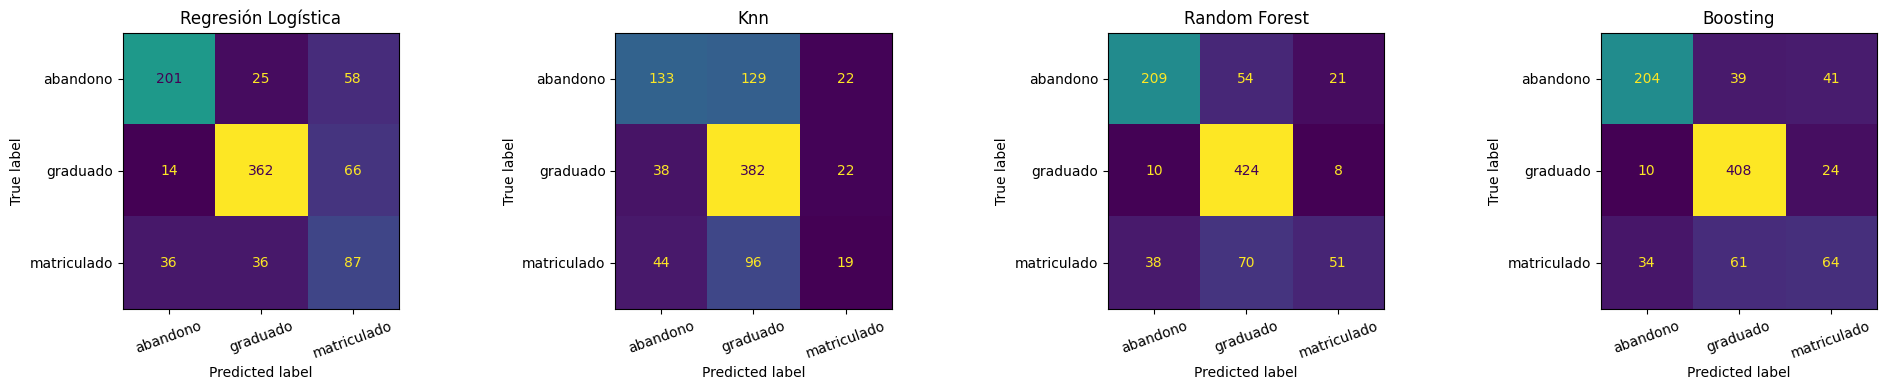

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20,4))

modelos_pred = [
    ('Regresión Logística', reg_log_pred),
    ('Knn', knn_pred),
    ('Random Forest', rf_pred),
    ('Boosting', gb_pred)
]

for ax, (nombre, y_pred) in zip(axes, modelos_pred):
    cm = confusion_matrix(y_test, y_pred, labels=sorted(y_test.unique()))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y_test.unique()))
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(nombre)
    ax.tick_params(axis='x', rotation= 20)

plt.tight_layout()
plt.savefig('../figuras/matrices_confusion_clf.png')
plt.show()

Tras seguir el estilo de las prácticas, hemos implementado las matrices de confusión para analizar mejor cada modelo y confirmar nuestras conclusiones de las métricas.
La clase 'graduado' es la más fácil de predecir para todos los modelos, ya que vemos una alta concentración de aciertos en la diagonal. Por el contrario, la clase 'matriculado' resulta ser la más compleja, con frecuentes confusiones tanto con 'abandono' como con 'graduado'.

También confirmamos que KNN representa el peor comportamiento, con una alta tasa de error en todas las clases, lo que confirma su inadecuación a este problema. 
Por el contrario, Random Forest distingue mejor 'graduado', pero Boosting tiene mejor identificación general, lo que lo hace el modelo más óptimo para este problema.

## 10. Curva ROC

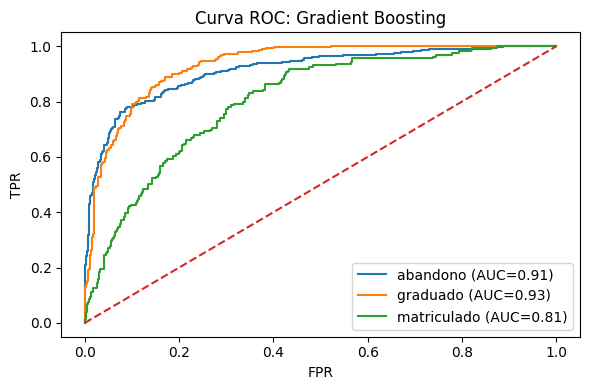

In [25]:
#importamos para poder crear la curva ROC
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import roc_curve, auc

#usamos el mejor modelo (Gradient Boosting) con predict_proba
lb = LabelBinarizer()
lb.fit(y_test )
y_test_bin = lb.transform(y_test)

y_prob = gb_fit.predict_proba(X_test)

fig, ax = plt.subplots(figsize=(6,4))

for i, clase in enumerate(gb_fit.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{clase} (AUC={roc_auc:.2f})')

ax.plot([0,1], [0,1], '--')
ax.set_title('Curva ROC: Gradient Boosting')
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')
ax.legend()

plt.tight_layout()
plt.savefig('../figuras/curva_roc_clf.png')
plt.show()

La curva ROC muestra un buen rendimiento del modelo en general, con valores de AUC elevados para 'abandono' (0.91) y 'graduado' (0.93).

Sin embargo, la clase matriculado presenta AUC ligeramente menor (0.81), lo que indica que es más difícil de distinguir del resto. Esto es coherente con lo que hemos obtenido antes

## 11. Scatter con PCA

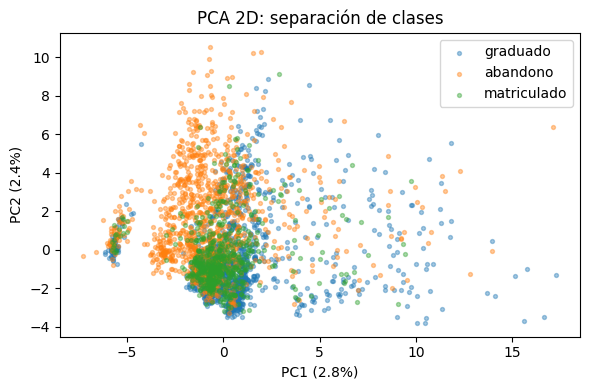

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_sc)

fig, ax = plt.subplots(figsize=(6,4))

for clase in y_train.unique():
    mask = y_train == clase
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, alpha=0.4, label=clase)

ax.set_title('PCA 2D: separación de clases')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.legend()

plt.tight_layout()
plt.savefig('../figuras/pca_solapamiento_clases.png')
plt.show()

Nuestra proyección PCA muestra un fuerte solpamiento entre las clases, especialmente en 'matriculado' que aparece mezclada con las otras dos.

Esto nos confirma la dificlutad del modelo para clasificar correctamente esta clase, ya que no existe una separación clara en el espacio de variables

## 12. Importancia de variables

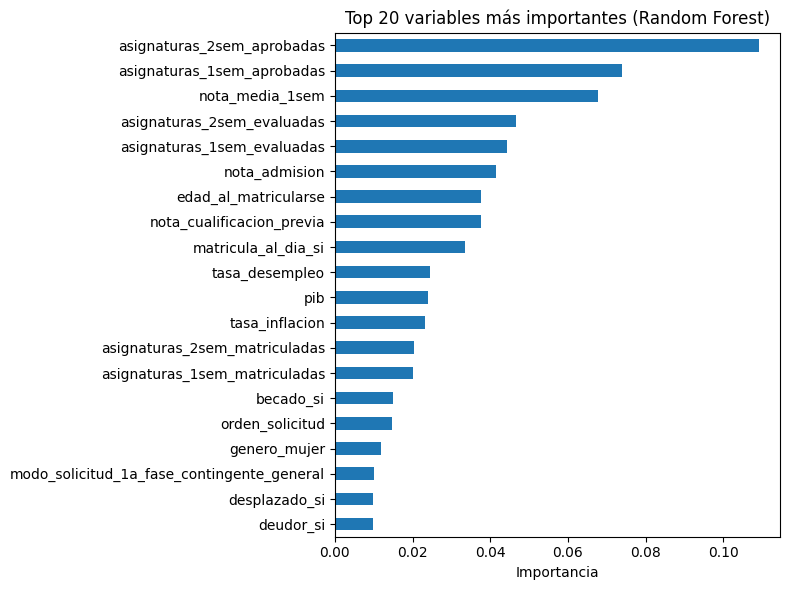

In [12]:
#solo para random forest, que es lo más natural y facil de interpretar
importancias = pd.Series(rf_fit.feature_importances_, index=X_train.columns)
top20 = importancias.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
top20.sort_values().plot(kind='barh')
plt.title('Top 20 variables más importantes (Random Forest)')
plt.xlabel('Importancia')
plt.tight_layout()
plt.savefig('../figuras/importancia_variables_clf.png')
plt.show()

Vemos que las variables más importantes están relacionadas con el rendimiento académico, espeicalmente asignaturas aprobads y notas. La codificación one-hot que hemos empleado distribuye la importancia de las variables categóricas en varias columnas.

## 13. Resumen para el informe

In [13]:
print("Resumen para el informe: TAREA 1: CLASIFICACION")

print("\nTabla comparativa: ")
print(df_resultados[['accuracy', 'F1 macro', 'F1 ponderado']].to_string())

print(f"\nMejor modelo: {mejor}")
print(f"\nAlgunas conclusiones: ")
print("La F1 macro se usa como métrica principal para el desbalanceo de clases")
print("Los modelos basados en árboles ofrecen buen rendimiento global")
print("La clase 'matriculado' es la más complicada de predecir")

Resumen para el informe: TAREA 1: CLASIFICACION

Tabla comparativa: 
                     accuracy  F1 macro  F1 ponderado
Regresión Logística    0.7345    0.6862        0.7436
KNN (k=7)              0.6034    0.4775        0.5656
Random Forest          0.7729    0.6853        0.7524
Gradient Boosting      0.7638    0.6901        0.7549

Mejor modelo: Gradient Boosting

Algunas conclusiones: 
La F1 macro se usa como métrica principal para el desbalanceo de clases
Los modelos basados en árboles ofrecen buen rendimiento global
La clase 'matriculado' es la más complicada de predecir
